# Bancada de testes — Redes Neurais no Adult Census Income

**Dataset:** [Adult Census Income](https://www.kaggle.com/datasets/uciml/adult-census-income) (UCI, censo dos EUA de 1994) · **Algoritmo:** rede neural do tipo perceptron multicamadas (MLP) · **Tarefa:** classificação binária — prever se a renda anual de uma pessoa é maior que 50 mil dólares (`>50K`).

O objetivo desta bancada é **testar, de forma controlada, as configurações da rede, as técnicas de tratamento dos dados e a engenharia de features** e descobrir qual combinação maximiza as métricas de avaliação: acurácia, precisão, recall, F1, ROC-AUC, PR-AUC e MCC.

Todo o código reutilizável (pré-processamento, rede, validação cruzada e registro dos resultados) está em [`bancada.ipynb`](bancada.ipynb). Este notebook apenas define e roda os experimentos.

## O que aprendemos com os notebooks de referência

Os dois notebooks analisados usam o mesmo dataset:

| Notebook | Pré-processamento | Modelo | Resultado |
|---|---|---|---|
| *EDA + Logistic Regression + PCA* | `?` → moda, `LabelEncoder`, `StandardScaler` | Regressão logística | acurácia 0,8218 (todas as features) |
| *T2-3 Adult Census Income tutorial* | `?` → moda / categoria `"null"`, `LabelEncoder`, `MinMaxScaler` | Árvore de decisão / Random Forest | acurácia 0,812 / 0,857 |

Pontos que esta bancada corrige ou investiga:

1. **Só a acurácia foi medida.** Como ~76% das pessoas ganham `<=50K`, um modelo que sempre responde `<=50K` já tem 76% de acurácia. Por isso medimos também precisão, recall, F1, ROC-AUC, PR-AUC e MCC.
2. **`LabelEncoder` em variáveis sem ordem** (ocupação, país, raça…) cria uma ordem falsa (ex.: `Sales` > `Prof-specialty`). Para árvores isso pouco importa, mas para modelos lineares e redes neurais costuma prejudicar. Testamos *one-hot*, *one-hot* com agrupamento de categorias raras e *target encoding*.
3. **Confusão entre componentes principais e colunas originais.** No notebook de PCA, a variância explicada pelo último *componente* foi usada para justificar a remoção da *coluna* `native.country` — mas cada componente é uma combinação de todas as colunas, então não há essa correspondência. Aqui o PCA é testado da forma correta: como uma etapa do pipeline que gera componentes.
4. **Vazamento de informação.** O tutorial calcula a moda do teste no próprio teste e ajusta o `LabelEncoder` com treino + teste juntos. Aqui todo o pré-processamento fica dentro de um `Pipeline` ajustado **somente nos dados de treino de cada fold**.
5. **Uma única divisão treino/validação** dá resultados ruidosos. Usamos **validação cruzada estratificada com 5 folds**, sempre com as mesmas divisões para todas as configurações (comparação justa).

## Bibliotecas

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report,
                             precision_recall_curve, roc_curve)
from sklearn.model_selection import ParameterSampler, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

%run bancada.ipynb   # funções e classes da bancada (bancada.ipynb, na mesma pasta)

# RANDOM_STATE = 42 (definido em bancada.ipynb): mesma semente em todo o notebook
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

# Cores dos gráficos (paleta categórica validada para daltonismo)
AZUL, LARANJA, VERDE_AGUA, AMARELO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
CINZA_TEXTO, CINZA_GRADE = "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": CINZA_TEXTO, "axes.labelcolor": CINZA_TEXTO,
    "xtick.color": CINZA_TEXTO, "ytick.color": CINZA_TEXTO,
    "axes.grid": True, "grid.color": CINZA_GRADE, "grid.linewidth": 0.8,
    "lines.linewidth": 2, "font.size": 10,
})

## Carregamento dos dados

A função `carregar_dados` baixa o dataset do Kaggle com `kagglehub`. Se não houver acesso ao Kaggle, ela usa um espelho do UCI no GitHub, que tem exatamente as mesmas 32.561 linhas. Os valores `?` (dado desconhecido) já são convertidos em `NaN`.

In [2]:
df = carregar_dados()
df.head()

Dados carregados de: espelho UCI no GitHub (mesmas linhas do Kaggle) -> 32561 linhas, 15 colunas


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [3]:
# Tipos das colunas e quantidade de valores não nulos
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       30725 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education.num   32561 non-null  int64
 5   marital.status  32561 non-null  str  
 6   occupation      30718 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital.gain    32561 non-null  int64
 11  capital.loss    32561 non-null  int64
 12  hours.per.week  32561 non-null  int64
 13  native.country  31978 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 3.7 MB


## Análise exploratória

Pontos que guiam os experimentos: o desbalanceamento do alvo, onde estão os valores faltantes, a assimetria das colunas de capital e a redundância entre `education` e `education.num`.

In [4]:
# Variável alvo: classes desbalanceadas (~76% x 24%)
print(df["income"].value_counts())
print()
print(df["income"].value_counts(normalize=True).round(3))

income
<=50K    24720
>50K      7841
Name: count, dtype: int64

income
<=50K    0.759
>50K     0.241
Name: proportion, dtype: float64


In [5]:
# Valores faltantes (antes eram '?'): só em 3 colunas categóricas
faltantes = df.isna().sum()
print(faltantes[faltantes > 0])
print("\nLinhas com pelo menos um faltante:", df.isna().any(axis=1).sum(),
      f"({df.isna().any(axis=1).mean():.1%})")

workclass         1836
occupation        1843
native.country     583
dtype: int64

Linhas com pelo menos um faltante: 2399 (7.4%)


In [6]:
# Taxa de renda > 50K entre quem tem e quem não tem o valor faltante:
# se a taxa muda, "faltar" é uma informação útil (motiva a categoria própria)
alvo = (df["income"] == ">50K")
for col in ["workclass", "occupation", "native.country"]:
    print(f"{col:<15} faltante: {alvo[df[col].isna()].mean():.3f}   "
          f"preenchido: {alvo[df[col].notna()].mean():.3f}")

workclass       faltante: 0.104   preenchido: 0.249
occupation      faltante: 0.104   preenchido: 0.249
native.country  faltante: 0.250   preenchido: 0.241


In [7]:
# Colunas numéricas: capital.gain e capital.loss são quase sempre zero e muito assimétricas
print(df.describe().T.round(1))
print("\nProporção de zeros:")
print((df[["capital.gain", "capital.loss"]] == 0).mean().round(3))

                  count      mean       std      min       25%       50%       75%        max
age             32561.0      38.6      13.6     17.0      28.0      37.0      48.0       90.0
fnlwgt          32561.0  189778.4  105550.0  12285.0  117827.0  178356.0  237051.0  1484705.0
education.num   32561.0      10.1       2.6      1.0       9.0      10.0      12.0       16.0
capital.gain    32561.0    1077.6    7385.3      0.0       0.0       0.0       0.0    99999.0
capital.loss    32561.0      87.3     403.0      0.0       0.0       0.0       0.0     4356.0
hours.per.week  32561.0      40.4      12.3      1.0      40.0      40.0      45.0       99.0

Proporção de zeros:
capital.gain    0.917
capital.loss    0.953
dtype: float64


In [8]:
# education e education.num carregam a mesma informação (uma categoria = um número)
print(df.groupby("education")["education.num"].nunique().max(),
      "valor de education.num por categoria de education")

1 valor de education.num por categoria de education


**Leitura da análise exploratória**

- O alvo é desbalanceado (24% de `>50K`): acurácia sozinha engana, e recall/F1 da classe `>50K` precisam ser acompanhados.
- Quem tem `workclass`/`occupation` faltante ganha `>50K` bem menos (10% contra 25%): o faltante é **informativo**. Isso motiva testar a categoria própria `Desconhecido`.
- `capital.gain` e `capital.loss` são zero para mais de 90% das pessoas e têm cauda longa: motivam testar log, escalonadores robustos e indicadores de "tem ganho/perda".
- `education` e `education.num` são a mesma informação (um número por categoria): motiva testar a remoção de `education`.

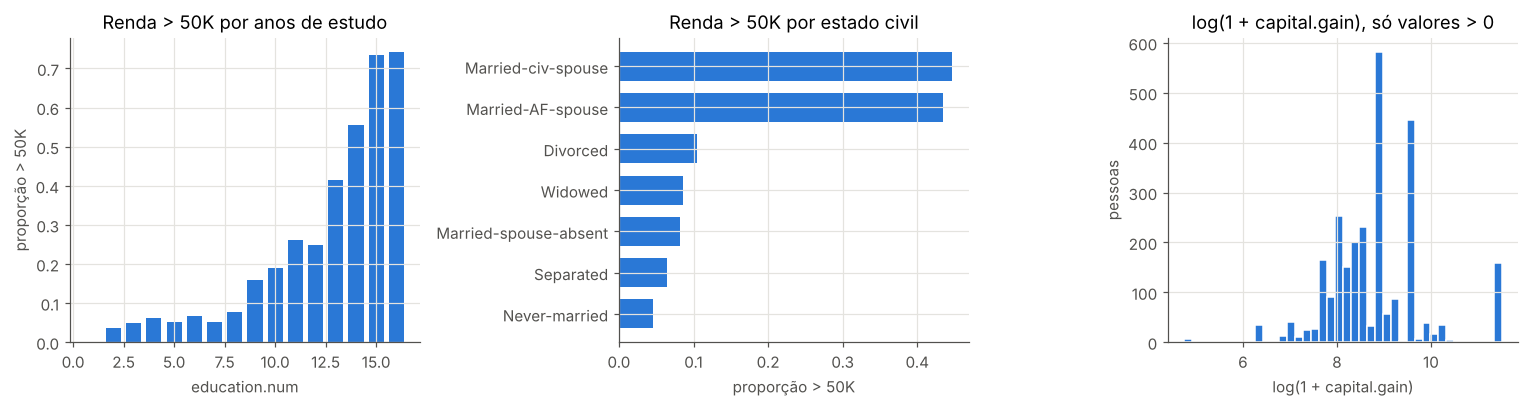

In [9]:
fig, eixos = plt.subplots(1, 3, figsize=(14, 3.8))

# Taxa de renda > 50K por anos de estudo
taxa = alvo.groupby(df["education.num"]).mean()
eixos[0].bar(taxa.index, taxa.values, color=AZUL, width=0.75)
eixos[0].set(title="Renda > 50K por anos de estudo", xlabel="education.num", ylabel="proporção > 50K")

# Taxa por estado civil
taxa = alvo.groupby(df["marital.status"]).mean().sort_values()
eixos[1].barh(taxa.index, taxa.values, color=AZUL, height=0.7)
eixos[1].set(title="Renda > 50K por estado civil", xlabel="proporção > 50K")

# Distribuição do ganho de capital (escala log por causa da assimetria)
ganho = df.loc[df["capital.gain"] > 0, "capital.gain"]
eixos[2].hist(np.log1p(ganho), bins=40, color=AZUL, edgecolor="white")
eixos[2].set(title="log(1 + capital.gain), só valores > 0", xlabel="log(1 + capital.gain)", ylabel="pessoas")
plt.tight_layout()
plt.show()

## Protocolo experimental

1. **Teste final separado (hold-out):** 20% dos dados, estratificado, guardado até o fim. Ele **não** é usado em nenhuma escolha.
2. **Validação cruzada estratificada (5 folds)** nos 80% restantes. Em cada fold, o pré-processamento é ajustado só no treino do fold, e 10% do treino do fold são reservados para a **parada antecipada** (o treino para quando a perda nesse conjunto deixa de cair por `paciencia` épocas, e os pesos da melhor época são restaurados).
3. **Busca gulosa em etapas:** cada etapa testa variações de **um** aspecto (faltantes, codificação, escala, features, PCA, arquitetura, regularização, ativação, otimização, balanceamento) sobre a melhor configuração encontrada até então. Ao final, uma **busca aleatória** refina os hiperparâmetros da rede em conjunto.
4. **Métrica de escolha: ROC-AUC.** Ela mede a capacidade do modelo de *ordenar* as pessoas por chance de ter renda alta, sem depender do limiar de decisão. Acurácia, precisão, recall e F1 dependem do limiar (0,5 durante as etapas); por isso o **limiar é otimizado numa etapa própria**, no fim, usando as previsões fora-do-fold.
5. **Todas as métricas são registradas** em cada experimento (média dos 5 folds; `roc_auc_dp` é o desvio-padrão entre folds).

A rede é o `MLPClassifier` do scikit-learn, treinado época a época por um laço próprio (`treinar_rede`, em `bancada.ipynb`) para termos parada antecipada pela perda de validação. Opções testadas da rede: nº de camadas e neurônios, ativação (`relu`, `tanh`, `logistic`), regularização L2, otimizador (`adam` ou SGD com momentum de Nesterov), taxa de aprendizado, tamanho do lote, redução da taxa de aprendizado em platôs e pesos por classe.

In [10]:
X, y = separar_x_y(df)   # y = 1 se renda > 50K

# Teste final (20%), estratificado: só será usado na última seção
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Treino:", X_treino.shape, " Teste:", X_teste.shape)
print(f"Proporção de > 50K -> treino: {y_treino.mean():.3f}  teste: {y_teste.mean():.3f}")

Treino: (26048, 14)  Teste: (6513, 14)
Proporção de > 50K -> treino: 0.241  teste: 0.241


In [11]:
# Configuração inicial: reproduz o pré-processamento dos notebooks de referência
# (moda nos faltantes + LabelEncoder + StandardScaler) com uma MLP de 2 camadas
pd.Series(CONFIG_BASE, name="valor").to_frame()

,valor
faltantes,moda
features,()
codificacao,label
escala,standard
pca,None
balanceamento,nenhum
camadas,"(64, 32)"
ativacao,relu
l2,0.0001
otimizador,adam


In [12]:
# pasta_cache: os resultados de cada configuração ficam salvos em disco; se o notebook
# for interrompido, rodá-lo de novo reaproveita o que já foi calculado
bancada = Bancada(X_treino, y_treino, n_folds=5, metrica_escolha="roc_auc",
                     pasta_cache="resultados/cache")
inicio_total = time.time()

## Etapa 0 — Linha de base

A rede com o pré-processamento dos notebooks de referência. Todos os ganhos seguintes são medidos em relação a ela.

In [13]:
tab = bancada.rodar_etapa("0. Linha de base", {"label + standard, MLP (64, 32)": {}})
tab

  label + standard, MLP (64, 32)         ROC-AUC=0.9022  F1=0.6510  Acc=0.8457  (6s)

>> Escolhida: label + standard, MLP (64, 32) (roc_auc = 0.9022)


,roc_auc,roc_auc_dp,pr_auc,acuracia,precisao,recall,f1,mcc,log_loss,epocas,tempo_s
experimento,,,,,,,,,,,
"label + standard, MLP (64, 32)",0.9022,0.0047,0.759,0.8457,0.7164,0.598,0.651,0.5574,0.327,27.8,5.6502


**Análise:** a rede com o pré-processamento dos notebooks de referência já supera a regressão logística deles, mas com recall de apenas ~0,60: de cada 10 pessoas com renda `>50K`, 4 não são encontradas no limiar 0,5. Ponto de partida: **ROC-AUC 0,9022, F1 0,651, acurácia 0,8457**.

## Etapa 1 — Valores faltantes

- **moda:** troca o faltante pela categoria mais frequente (como nos notebooks de referência);
- **categoria:** cria a categoria `Desconhecido` — preserva a informação de que o dado faltava;
- **remover:** descarta do treino as linhas com faltantes (~7% delas). Na validação/teste, que não podem perder linhas, o faltante recebe a moda.

In [14]:
tab = bancada.rodar_etapa("1. Faltantes", {
    "moda": {"faltantes": "moda"},
    "categoria 'Desconhecido'": {"faltantes": "categoria"},
    "remover linhas (treino)": {"faltantes": "remover"},
})
tab

  moda                                   ROC-AUC=0.9022  F1=0.6510  Acc=0.8457  (6s)
  categoria 'Desconhecido'               ROC-AUC=0.9019  F1=0.6497  Acc=0.8452  (5s)
  remover linhas (treino)                ROC-AUC=0.9016  F1=0.6531  Acc=0.8471  (4s)

>> Escolhida: moda (roc_auc = 0.9022)


,roc_auc,roc_auc_dp,pr_auc,acuracia,precisao,recall,f1,mcc,log_loss,epocas,tempo_s
experimento,,,,,,,,,,,
moda,0.9022,0.0047,0.7590,0.8457,0.7164,0.5980,0.6510,0.5574,0.3270,27.8,5.6502
categoria 'Desconhecido',0.9019,0.0047,0.7594,0.8452,0.7153,0.5965,0.6497,0.5558,0.3271,25.8,4.5187
remover linhas (treino),0.9016,0.0056,0.7573,0.8471,0.7203,0.5980,0.6531,0.5603,0.3277,26.2,4.4327


**Análise:** as três estratégias ficam a menos de 0,001 de ROC-AUC uma da outra, bem abaixo do desvio-padrão entre folds (~0,005). Para esta rede, **a forma de tratar os faltantes não importa** (os faltantes estão em apenas 7% das linhas). Mantemos a moda, a opção mais simples.

## Etapa 2 — Codificação das variáveis categóricas

- **label:** um inteiro por categoria (ordem arbitrária) + padronização;
- **onehot:** uma coluna 0/1 por categoria (sem ordem falsa; ~100 colunas);
- **onehot_raras:** *one-hot*, mas categorias com menos de 0,5% das linhas viram uma só (`infrequent`) — reduz colunas quase vazias (vários países);
- **target:** cada categoria vira a proporção de renda > 50K dentro dela (calculada com validação cruzada interna para não vazar o alvo).

In [15]:
tab = bancada.rodar_etapa("2. Codificação", {
    "label": {"codificacao": "label"},
    "onehot": {"codificacao": "onehot"},
    "onehot + raras agrupadas": {"codificacao": "onehot_raras"},
    "target encoding": {"codificacao": "target"},
})
tab

  label                                  ROC-AUC=0.9022  F1=0.6510  Acc=0.8457  (6s)
  onehot                                 ROC-AUC=0.9117  F1=0.6753  Acc=0.8534  (3s)
  onehot + raras agrupadas               ROC-AUC=0.9114  F1=0.6743  Acc=0.8538  (3s)
  target encoding                        ROC-AUC=0.9100  F1=0.6655  Acc=0.8529  (4s)

>> Escolhida: onehot (roc_auc = 0.9117)


,roc_auc,roc_auc_dp,pr_auc,acuracia,precisao,recall,f1,mcc,log_loss,epocas,tempo_s
experimento,,,,,,,,,,,
onehot,0.9117,0.0050,0.7775,0.8534,0.7252,0.6330,0.6753,0.5840,0.3119,8.4,2.9991
onehot + raras agrupadas,0.9114,0.0042,0.7774,0.8538,0.7288,0.6290,0.6743,0.5841,0.3125,11.6,2.5580
target encoding,0.9100,0.0058,0.7736,0.8529,0.7368,0.6078,0.6655,0.5771,0.3149,27.0,4.4207
label,0.9022,0.0047,0.7590,0.8457,0.7164,0.5980,0.6510,0.5574,0.3270,27.8,5.6502


**Análise:** este é o **maior ganho da bancada**. Trocar o `LabelEncoder` por *one-hot* aumenta a ROC-AUC de 0,9022 para 0,9117 (+0,0095), o F1 de 0,651 para 0,675 e a acurácia de 0,846 para 0,853. Com o rótulo inteiro, a rede precisa "desfazer" uma ordem que não existe; com *one-hot* cada categoria tem o seu próprio peso. A rede também converge muito mais rápido (8 épocas em vez de 28). O *target encoding* fica perto (0,9100) e agrupar as categorias raras não muda o resultado (0,9114) — pode ser útil para reduzir o número de colunas sem perder desempenho.

## Etapa 3 — Escala das variáveis numéricas

Redes neurais são sensíveis à escala das entradas. Além dos escalonadores, testamos aplicar **log(1 + x)** em `capital.gain` e `capital.loss` antes da padronização, para reduzir a assimetria vista na análise exploratória. `quantile` e `power` (Yeo-Johnson) também deixam as distribuições mais simétricas.

In [16]:
features_atuais = tuple(bancada.melhor_cfg["features"])
tab = bancada.rodar_etapa("3. Escala", {
    "standard": {"escala": "standard"},
    "minmax": {"escala": "minmax"},
    "robust": {"escala": "robust"},
    "quantile (saída normal)": {"escala": "quantile"},
    "power (Yeo-Johnson)": {"escala": "power"},
    "standard + log capital": {"escala": "standard", "features": features_atuais + ("log_capital",)},
    "minmax + log capital": {"escala": "minmax", "features": features_atuais + ("log_capital",)},
})
tab

  standard                               ROC-AUC=0.9117  F1=0.6753  Acc=0.8534  (3s)
  minmax                                 ROC-AUC=0.9032  F1=0.6656  Acc=0.8482  (4s)
  robust                                 ROC-AUC=0.9076  F1=0.6737  Acc=0.8506  (4s)
  quantile (saída normal)                ROC-AUC=0.9099  F1=0.6823  Acc=0.8552  (4s)
  power (Yeo-Johnson)                    ROC-AUC=0.9042  F1=0.6638  Acc=0.8471  (4s)
  standard + log capital                 ROC-AUC=0.9064  F1=0.6687  Acc=0.8497  (3s)
  minmax + log capital                   ROC-AUC=0.8995  F1=0.6550  Acc=0.8448  (3s)

>> Escolhida: standard (roc_auc = 0.9117)


,roc_auc,roc_auc_dp,pr_auc,acuracia,precisao,recall,f1,mcc,log_loss,epocas,tempo_s
experimento,,,,,,,,,,,
standard,0.9117,0.0050,0.7775,0.8534,0.7252,0.6330,0.6753,0.5840,0.3119,8.4,2.9991
quantile (saída normal),0.9099,0.0065,0.7741,0.8552,0.7238,0.6459,0.6823,0.5908,0.3151,17.4,4.2411
robust,0.9076,0.0044,0.7651,0.8506,0.7125,0.6405,0.6737,0.5793,0.3331,12.4,3.5675
standard + log capital,0.9064,0.0059,0.7573,0.8497,0.7143,0.6298,0.6687,0.5744,0.3215,9.6,2.8397
power (Yeo-Johnson),0.9042,0.0054,0.7466,0.8471,0.7078,0.6265,0.6638,0.5678,0.3254,8.0,3.6737
minmax,0.9032,0.0058,0.7563,0.8482,0.7100,0.6281,0.6656,0.5704,0.3266,15.2,3.8517
minmax + log capital,0.8995,0.0062,0.7414,0.8448,0.7063,0.6133,0.6550,0.5590,0.3331,11.4,3.1937


**Análise:** o `StandardScaler` vence em ROC-AUC. O `QuantileTransformer` dá F1 e acurácia um pouco maiores no limiar 0,5, mas ordena pior as pessoas (ROC-AUC 0,9099) — e o limiar será ajustado depois. O `MinMaxScaler` (usado no tutorial) é o pior entre os escalonadores: os poucos valores extremos de `capital.gain` (até 99.999) achatam todos os outros perto de zero.

O **log nas colunas de capital piorou** a ROC-AUC (−0,005). O log aproxima valores muito diferentes (ex.: 5.000 e 15.000), mas para a renda o que importa é justamente o valor exato: ganhos de capital acima de ~7.000 quase garantem renda `>50K`. A Etapa 4 mostra que a informação útil é, sobretudo, *ter ou não* ganho de capital.

## Etapa 4 — Engenharia de features

Primeiro, cada transformação é testada **sozinha** sobre a configuração atual (sem adotar). Depois, testamos a **combinação** das que ajudaram individualmente e uma seleção gulosa (adicionando, uma a uma, as que mais ajudaram enquanto houver ganho).

| Opção | O que faz |
|---|---|
| `remover_education` | remove `education` (mesma informação de `education.num`) |
| `remover_fnlwgt` | remove o peso amostral do censo (não descreve a pessoa) |
| `capital_liquido` | cria `capital.net = capital.gain − capital.loss` |
| `flags_capital` | cria indicadores 0/1 de ter ganho e de ter perda de capital |
| `log_capital` | log(1 + x) nas colunas de capital |
| `agrupar_pais` | `native.country` → Estados Unidos × Outro |
| `agrupar_estado_civil` | 7 estados civis → Casado, Separado, Viúvo, Solteiro |
| `agrupar_setor` | `workclass` → Governo, Privado, Autônomo, Autônomo-inc, Sem renda |
| `faixas_idade_horas` | faixas de idade e de horas semanais (categóricas) |
| `interacoes` | idade × escolaridade e horas × escolaridade |

In [17]:
OPCOES_FEATURES = ["remover_education", "remover_fnlwgt", "capital_liquido", "flags_capital",
                   "log_capital", "agrupar_pais", "agrupar_estado_civil", "agrupar_setor",
                   "faixas_idade_horas", "interacoes"]

atuais = tuple(bancada.melhor_cfg["features"])
candidatas = [o for o in OPCOES_FEATURES if o not in atuais]
variacoes = {"atual": {}}
variacoes.update({f"+ {o}": {"features": atuais + (o,)} for o in candidatas})

tab_individual = bancada.rodar_etapa("4a. Features (uma a uma)", variacoes, adotar=False)
tab_individual

  atual                                  ROC-AUC=0.9117  F1=0.6753  Acc=0.8534  (3s)
  + remover_education                    ROC-AUC=0.9117  F1=0.6788  Acc=0.8560  (3s)
  + remover_fnlwgt                       ROC-AUC=0.9112  F1=0.6750  Acc=0.8544  (3s)
  + capital_liquido                      ROC-AUC=0.9114  F1=0.6763  Acc=0.8542  (3s)
  + flags_capital                        ROC-AUC=0.9137  F1=0.6823  Acc=0.8566  (3s)
  + log_capital                          ROC-AUC=0.9064  F1=0.6687  Acc=0.8497  (3s)
  + agrupar_pais                         ROC-AUC=0.9117  F1=0.6744  Acc=0.8537  (3s)
  + agrupar_estado_civil                 ROC-AUC=0.9114  F1=0.6793  Acc=0.8552  (3s)
  + agrupar_setor                        ROC-AUC=0.9112  F1=0.6756  Acc=0.8543  (3s)
  + faixas_idade_horas                   ROC-AUC=0.9114  F1=0.6754  Acc=0.8537  (3s)
  + interacoes                           ROC-AUC=0.9121  F1=0.6769  Acc=0.8550  (3s)


,roc_auc,roc_auc_dp,pr_auc,acuracia,precisao,recall,f1,mcc,log_loss,epocas,tempo_s
experimento,,,,,,,,,,,
+ flags_capital,0.9137,0.0050,0.7841,0.8566,0.7326,0.6396,0.6823,0.5930,0.3086,10.2,3.4563
+ interacoes,0.9121,0.0050,0.7784,0.8550,0.7316,0.6308,0.6769,0.5872,0.3109,9.0,2.9772
+ remover_education,0.9117,0.0050,0.7772,0.8560,0.7343,0.6321,0.6788,0.5899,0.3121,8.8,3.1189
+ agrupar_pais,0.9117,0.0048,0.7775,0.8537,0.7276,0.6292,0.6744,0.5836,0.3116,11.4,2.8834
atual,0.9117,0.0050,0.7775,0.8534,0.7252,0.6330,0.6753,0.5840,0.3119,8.4,2.9991
+ capital_liquido,0.9114,0.0046,0.7770,0.8542,0.7273,0.6329,0.6763,0.5855,0.3123,10.6,3.4337
+ agrupar_estado_civil,0.9114,0.0052,0.7766,0.8552,0.7293,0.6370,0.6793,0.5892,0.3124,8.8,3.1458
+ faixas_idade_horas,0.9114,0.0051,0.7763,0.8537,0.7264,0.6326,0.6754,0.5845,0.3122,9.4,2.9589
+ remover_fnlwgt,0.9112,0.0055,0.7765,0.8544,0.7312,0.6282,0.6750,0.5853,0.3131,10.8,2.8709


In [18]:
# Ganho de ROC-AUC de cada opção em relação à configuração atual
ref = tab_individual.loc["atual", "roc_auc"]
ganhos = (tab_individual["roc_auc"].drop("atual") - ref).sort_values(ascending=False)
ganhos.index = ganhos.index.str.replace("+ ", "", regex=False)
print(ganhos.round(4).to_string())
uteis = [o for o in ganhos.index if ganhos[o] > 0]
print("\nOpções que ajudaram sozinhas:", uteis)

experimento
flags_capital           0.0020
interacoes              0.0004
remover_education       0.0000
agrupar_pais            0.0000
capital_liquido        -0.0003
agrupar_estado_civil   -0.0003
faixas_idade_horas     -0.0003
remover_fnlwgt         -0.0005
agrupar_setor          -0.0005
log_capital            -0.0053

Opções que ajudaram sozinhas: ['flags_capital', 'interacoes']


**Análise:** apenas `flags_capital` (+0,0020) e `interacoes` (+0,0004) melhoraram a ROC-AUC sozinhas. As outras ficam dentro do ruído ou pioram: agrupar categorias joga fora detalhes que a rede consegue aproveitar com *one-hot*, e remover `education`/`fnlwgt` não muda nada (a rede já aprende a ignorá-las).

In [19]:
# Seleção gulosa: adiciona as opções na ordem do ganho individual,
# mantendo cada uma só se a ROC-AUC da combinação melhorar
selecionadas, melhor_auc = list(atuais), ref
for opcao in uteis:
    cfg = {**bancada.melhor_cfg, "features": tuple(selecionadas + [opcao])}
    linha = bancada.avaliar(cfg, "4b. Features (seleção gulosa)", f"+ {opcao}")
    manter = linha["roc_auc"] > melhor_auc
    print(f"  + {opcao:<22} ROC-AUC={linha['roc_auc']:.4f}  -> {'mantém' if manter else 'descarta'}")
    if manter:
        selecionadas.append(opcao)
        melhor_auc = linha["roc_auc"]
print("\nSeleção gulosa:", selecionadas)

  + flags_capital          ROC-AUC=0.9137  -> mantém
  + interacoes             ROC-AUC=0.9132  -> descarta

Seleção gulosa: ['flags_capital']


In [20]:
tab = bancada.rodar_etapa("4c. Features (combinações)", {
    "atual": {},
    "todas as úteis juntas": {"features": tuple(dict.fromkeys(list(atuais) + uteis))},
    "seleção gulosa": {"features": tuple(selecionadas)},
    "todas as opções": {"features": tuple(OPCOES_FEATURES)},
})
tab

  atual                                  ROC-AUC=0.9117  F1=0.6753  Acc=0.8534  (3s)
  todas as úteis juntas                  ROC-AUC=0.9132  F1=0.6815  Acc=0.8565  (3s)
  seleção gulosa                         ROC-AUC=0.9137  F1=0.6823  Acc=0.8566  (3s)
  todas as opções                        ROC-AUC=0.9102  F1=0.6755  Acc=0.8533  (4s)

>> Escolhida: seleção gulosa (roc_auc = 0.9137)


,roc_auc,roc_auc_dp,pr_auc,acuracia,precisao,recall,f1,mcc,log_loss,epocas,tempo_s
experimento,,,,,,,,,,,
seleção gulosa,0.9137,0.0050,0.7841,0.8566,0.7326,0.6396,0.6823,0.5930,0.3086,10.2,3.4563
todas as úteis juntas,0.9132,0.0048,0.7838,0.8565,0.7332,0.6373,0.6815,0.5922,0.3092,12.2,3.4052
atual,0.9117,0.0050,0.7775,0.8534,0.7252,0.6330,0.6753,0.5840,0.3119,8.4,2.9991
todas as opções,0.9102,0.0041,0.7752,0.8533,0.7235,0.6338,0.6755,0.5836,0.3130,20.6,4.3513


**Análise:** a melhor combinação é **apenas o indicador de ganho/perda de capital** (ROC-AUC 0,9137, F1 0,682). Somar as interações não ajudou, e **usar todas as transformações juntas piorou** (0,9102): mais features não significam um modelo melhor. A rede já cria internamente as combinações não lineares de que precisa; o que ajuda é a informação que ela teria dificuldade de extrair sozinha — o salto entre "nenhum ganho" (92% das pessoas) e "algum ganho".

## Etapa 5 — PCA

Testamos a ideia do notebook de referência da forma correta: o PCA entra no pipeline **depois** da codificação e da escala, e a rede recebe apenas os componentes que explicam 99%, 95% ou 90% da variância.

In [21]:
tab = bancada.rodar_etapa("5. PCA", {
    "sem PCA": {"pca": None},
    "PCA 99% da variância": {"pca": 0.99},
    "PCA 95% da variância": {"pca": 0.95},
    "PCA 90% da variância": {"pca": 0.90},
})
tab

  sem PCA                                ROC-AUC=0.9137  F1=0.6823  Acc=0.8566  (3s)
  PCA 99% da variância                   ROC-AUC=0.9121  F1=0.6805  Acc=0.8554  (4s)
  PCA 95% da variância                   ROC-AUC=0.9113  F1=0.6764  Acc=0.8539  (3s)
  PCA 90% da variância                   ROC-AUC=0.9097  F1=0.6663  Acc=0.8509  (4s)

>> Escolhida: sem PCA (roc_auc = 0.9137)


,roc_auc,roc_auc_dp,pr_auc,acuracia,precisao,recall,f1,mcc,log_loss,epocas,tempo_s
experimento,,,,,,,,,,,
sem PCA,0.9137,0.0050,0.7841,0.8566,0.7326,0.6396,0.6823,0.5930,0.3086,10.2,3.4563
PCA 99% da variância,0.9121,0.0042,0.7810,0.8554,0.7281,0.6394,0.6805,0.5899,0.3121,14.4,3.6444
PCA 95% da variância,0.9113,0.0037,0.7792,0.8539,0.7264,0.6337,0.6764,0.5852,0.3124,14.6,3.2912
PCA 90% da variância,0.9097,0.0029,0.7766,0.8509,0.7242,0.6185,0.6663,0.5747,0.3144,18.4,3.5972


**Análise:** o PCA **piora** a rede, e quanto menos componentes, pior (0,9137 → 0,9121 → 0,9113 → 0,9097). O PCA escolhe as direções de maior variância **sem olhar o alvo**, então pode descartar direções pequenas que são justamente as mais preditivas. Com ~100 colunas e 26 mil linhas não há "maldição da dimensionalidade" a combater: o PCA só faz sentido aqui para reduzir custo, não para melhorar as métricas.

## Etapa 6 — Arquitetura (profundidade e largura)

Número de camadas ocultas e de neurônios por camada, do mais simples (uma camada com 16 neurônios) ao mais complexo (3 camadas, 256-128-64).

In [22]:
ARQUITETURAS = [(16,), (32,), (64,), (128,), (256,),
                (32, 16), (64, 32), (128, 64), (256, 128),
                (64, 64, 64), (128, 64, 32), (256, 128, 64)]
tab = bancada.rodar_etapa("6. Arquitetura", {str(a): {"camadas": a} for a in ARQUITETURAS})
tab

  (16,)                                  ROC-AUC=0.9136  F1=0.6810  Acc=0.8569  (3s)
  (32,)                                  ROC-AUC=0.9139  F1=0.6850  Acc=0.8581  (3s)
  (64,)                                  ROC-AUC=0.9142  F1=0.6845  Acc=0.8577  (4s)
  (128,)                                 ROC-AUC=0.9143  F1=0.6821  Acc=0.8575  (5s)
  (256,)                                 ROC-AUC=0.9144  F1=0.6836  Acc=0.8583  (6s)
  (32, 16)                               ROC-AUC=0.9137  F1=0.6813  Acc=0.8568  (3s)
  (64, 32)                               ROC-AUC=0.9137  F1=0.6823  Acc=0.8566  (3s)
  (128, 64)                              ROC-AUC=0.9139  F1=0.6810  Acc=0.8575  (5s)
  (256, 128)                             ROC-AUC=0.9135  F1=0.6793  Acc=0.8564  (8s)
  (64, 64, 64)                           ROC-AUC=0.9129  F1=0.6790  Acc=0.8547  (4s)
  (128, 64, 32)                          ROC-AUC=0.9137  F1=0.6849  Acc=0.8573  (4s)
  (256, 128, 64)                         ROC-AUC=0.9133  F1=0.676

,roc_auc,roc_auc_dp,pr_auc,acuracia,precisao,recall,f1,mcc,log_loss,epocas,tempo_s
experimento,,,,,,,,,,,
"(256,)",0.9144,0.0049,0.7864,0.8583,0.7401,0.6359,0.6836,0.5962,0.3073,11.6,6.0434
"(128,)",0.9143,0.0049,0.7856,0.8575,0.7377,0.6349,0.6821,0.5940,0.3082,15.4,4.5456
"(64,)",0.9142,0.0048,0.7853,0.8577,0.7351,0.6408,0.6845,0.5957,0.3081,21.8,4.1973
"(128, 64)",0.9139,0.0049,0.7853,0.8575,0.7392,0.6319,0.6810,0.5932,0.3084,7.6,4.5430
"(32,)",0.9139,0.0046,0.7848,0.8581,0.7368,0.6404,0.6850,0.5966,0.3087,29.8,3.2963
"(64, 32)",0.9137,0.0050,0.7841,0.8566,0.7326,0.6396,0.6823,0.5930,0.3086,10.2,3.4563
"(128, 64, 32)",0.9137,0.0053,0.7847,0.8573,0.7330,0.6440,0.6849,0.5958,0.3088,6.0,4.2455
"(32, 16)",0.9137,0.0046,0.7855,0.8568,0.7348,0.6357,0.6813,0.5924,0.3073,15.6,2.7522
"(16,)",0.9136,0.0045,0.7841,0.8569,0.7363,0.6343,0.6810,0.5925,0.3091,45.6,3.4034


**Análise:** todas as arquiteturas ficam entre 0,9129 e 0,9144 — uma faixa estreita, de poucos desvios-padrão do ruído entre sementes (~0,0005, ver a seção de estabilidade). **Uma camada oculta basta** para este problema; redes mais profundas sobreajustam muito rápido (a de 256-128-64 para em ~4 épocas) sem ganho. A camada única de 256 neurônios foi a melhor (0,9144) e, por ser larga, se beneficia de regularização (próxima etapa).

## Etapa 7 — Regularização

- **L2 (`alpha`)**: penaliza pesos grandes, reduzindo o sobreajuste;
- **paciência** da parada antecipada: quantas épocas sem melhora esperar antes de parar.

In [23]:
variacoes = {f"L2 = {a:g}": {"l2": a} for a in [0.0, 1e-5, 1e-4, 1e-3, 1e-2, 3e-2, 1e-1, 3e-1, 1.0]}
tab = bancada.rodar_etapa("7a. Regularização L2", variacoes)
tab

  L2 = 0                                 ROC-AUC=0.9144  F1=0.6828  Acc=0.8579  (6s)
  L2 = 1e-05                             ROC-AUC=0.9144  F1=0.6823  Acc=0.8577  (6s)
  L2 = 0.0001                            ROC-AUC=0.9144  F1=0.6836  Acc=0.8583  (6s)
  L2 = 0.001                             ROC-AUC=0.9145  F1=0.6841  Acc=0.8584  (6s)
  L2 = 0.01                              ROC-AUC=0.9146  F1=0.6831  Acc=0.8580  (6s)
  L2 = 0.03                              ROC-AUC=0.9147  F1=0.6814  Acc=0.8573  (7s)
  L2 = 0.1                               ROC-AUC=0.9147  F1=0.6799  Acc=0.8571  (9s)
  L2 = 0.3                               ROC-AUC=0.9150  F1=0.6807  Acc=0.8581  (23s)
  L2 = 1                                 ROC-AUC=0.9118  F1=0.6691  Acc=0.8550  (27s)

>> Escolhida: L2 = 0.3 (roc_auc = 0.9150)


,roc_auc,roc_auc_dp,pr_auc,acuracia,precisao,recall,f1,mcc,log_loss,epocas,tempo_s
experimento,,,,,,,,,,,
L2 = 0.3,0.9150,0.0048,0.7886,0.8581,0.7440,0.6284,0.6807,0.5943,0.3059,85.4,23.0747
L2 = 0.1,0.9147,0.0048,0.7881,0.8571,0.7391,0.6305,0.6799,0.5923,0.3065,23.6,9.0153
L2 = 0.03,0.9147,0.0047,0.7873,0.8573,0.7374,0.6341,0.6814,0.5933,0.3065,15.2,7.0329
L2 = 0.01,0.9146,0.0048,0.7869,0.8580,0.7391,0.6357,0.6831,0.5954,0.3070,13.2,6.4995
L2 = 0.001,0.9145,0.0049,0.7863,0.8584,0.7399,0.6370,0.6841,0.5966,0.3072,11.8,6.1417
L2 = 0.0001,0.9144,0.0049,0.7864,0.8583,0.7401,0.6359,0.6836,0.5962,0.3073,11.6,6.0434
L2 = 1e-05,0.9144,0.0048,0.7862,0.8577,0.7386,0.6348,0.6823,0.5945,0.3074,12.0,6.1944
L2 = 0,0.9144,0.0048,0.7862,0.8579,0.7390,0.6353,0.6828,0.5950,0.3074,12.0,5.9717
L2 = 1,0.9118,0.0045,0.7781,0.8550,0.7436,0.6088,0.6691,0.5825,0.3121,108.0,26.6184


**Análise:** com a rede larga, aumentar a penalidade L2 até 0,3 ajuda um pouco (0,9144 → 0,9150) e reduz a log loss. Com L2 = 1 a rede fica rígida demais (subajuste: 0,9118). A regularização faz a rede treinar por mais épocas (85 em vez de 12) sem sobreajustar.

In [24]:
tab = bancada.rodar_etapa("7b. Paciência", {f"paciência = {p}": {"paciencia": p} for p in [5, 10, 20, 30]})
tab

  paciência = 5                          ROC-AUC=0.9149  F1=0.6803  Acc=0.8580  (15s)
  paciência = 10                         ROC-AUC=0.9150  F1=0.6807  Acc=0.8581  (23s)
  paciência = 20                         ROC-AUC=0.9150  F1=0.6803  Acc=0.8581  (29s)
  paciência = 30                         ROC-AUC=0.9150  F1=0.6797  Acc=0.8580  (30s)

>> Escolhida: paciência = 30 (roc_auc = 0.9150)


,roc_auc,roc_auc_dp,pr_auc,acuracia,precisao,recall,f1,mcc,log_loss,epocas,tempo_s
experimento,,,,,,,,,,,
paciência = 30,0.9150,0.0048,0.7887,0.8580,0.7445,0.6262,0.6797,0.5934,0.3057,121.4,29.8432
paciência = 20,0.9150,0.0048,0.7887,0.8581,0.7445,0.6273,0.6803,0.5940,0.3058,107.4,29.3927
paciência = 10,0.9150,0.0048,0.7886,0.8581,0.7440,0.6284,0.6807,0.5943,0.3059,85.4,23.0747
paciência = 5,0.9149,0.0048,0.7883,0.8580,0.7440,0.6278,0.6803,0.5939,0.3061,57.8,14.9994


**Análise:** a paciência praticamente não muda o resultado (0,9149 a 0,9150), porque os pesos da melhor época são sempre restaurados. Paciências maiores só custam mais tempo.

## Etapa 8 — Função de ativação

In [25]:
tab = bancada.rodar_etapa("8. Ativação", {a: {"ativacao": a} for a in ["relu", "tanh", "logistic"]})
tab

  relu                                   ROC-AUC=0.9150  F1=0.6797  Acc=0.8580  (30s)
  tanh                                   ROC-AUC=0.9146  F1=0.6797  Acc=0.8585  (48s)
  logistic                               ROC-AUC=0.9043  F1=0.6513  Acc=0.8485  (58s)

>> Escolhida: relu (roc_auc = 0.9150)


,roc_auc,roc_auc_dp,pr_auc,acuracia,precisao,recall,f1,mcc,log_loss,epocas,tempo_s
experimento,,,,,,,,,,,
relu,0.9150,0.0048,0.7887,0.8580,0.7445,0.6262,0.6797,0.5934,0.3057,121.4,29.8432
tanh,0.9146,0.0050,0.7866,0.8585,0.7481,0.6236,0.6797,0.5942,0.3067,199.6,47.7473
logistic,0.9043,0.0053,0.7587,0.8485,0.7309,0.5890,0.6513,0.5621,0.3255,196.8,58.1712


**Análise:** `relu` e `tanh` são equivalentes (0,9150 × 0,9146). A `logistic` (sigmoide) é claramente pior (0,9043) e mais lenta: ela satura e seus gradientes ficam pequenos, o que dificulta o treino.

## Etapa 9 — Otimização

Otimizador e taxa de aprendizado são testados juntos, porque a melhor taxa depende do otimizador. Depois, o tamanho do lote e a redução da taxa de aprendizado quando a perda de validação estaciona (*ReduceLROnPlateau*).

In [26]:
variacoes = {f"adam, lr = {lr:g}": {"otimizador": "adam", "lr": lr} for lr in [1e-4, 3e-4, 1e-3, 3e-3, 1e-2]}
variacoes.update({f"sgd + nesterov, lr = {lr:g}": {"otimizador": "sgd", "lr": lr} for lr in [3e-3, 1e-2, 3e-2, 1e-1]})
tab = bancada.rodar_etapa("9a. Otimizador e taxa de aprendizado", variacoes)
tab

  adam, lr = 0.0001                      ROC-AUC=0.9152  F1=0.6793  Acc=0.8577  (54s)
  adam, lr = 0.0003                      ROC-AUC=0.9154  F1=0.6838  Acc=0.8585  (44s)
  adam, lr = 0.001                       ROC-AUC=0.9150  F1=0.6797  Acc=0.8580  (30s)
  adam, lr = 0.003                       ROC-AUC=0.9144  F1=0.6820  Acc=0.8584  (28s)
  adam, lr = 0.01                        ROC-AUC=0.9124  F1=0.6789  Acc=0.8573  (24s)
  sgd + nesterov, lr = 0.003             ROC-AUC=0.9147  F1=0.6786  Acc=0.8573  (51s)
  sgd + nesterov, lr = 0.01              ROC-AUC=0.9153  F1=0.6836  Acc=0.8586  (51s)
  sgd + nesterov, lr = 0.03              ROC-AUC=0.9150  F1=0.6809  Acc=0.8574  (28s)
  sgd + nesterov, lr = 0.1               ROC-AUC=0.9141  F1=0.6763  Acc=0.8551  (21s)

>> Escolhida: adam, lr = 0.0003 (roc_auc = 0.9154)


,roc_auc,roc_auc_dp,pr_auc,acuracia,precisao,recall,f1,mcc,log_loss,epocas,tempo_s
experimento,,,,,,,,,,,
"adam, lr = 0.0003",0.9154,0.0048,0.7892,0.8585,0.7410,0.6351,0.6838,0.5964,0.3050,146.0,43.7385
"sgd + nesterov, lr = 0.01",0.9153,0.0046,0.7890,0.8586,0.7419,0.6343,0.6836,0.5965,0.3053,183.8,51.3216
"adam, lr = 0.0001",0.9152,0.0044,0.7884,0.8577,0.7431,0.6259,0.6793,0.5924,0.3053,199.6,54.1256
"adam, lr = 0.001",0.9150,0.0048,0.7887,0.8580,0.7445,0.6262,0.6797,0.5934,0.3057,121.4,29.8432
"sgd + nesterov, lr = 0.03",0.9150,0.0046,0.7887,0.8574,0.7395,0.6318,0.6809,0.5932,0.3059,104.2,27.8255
"sgd + nesterov, lr = 0.003",0.9147,0.0042,0.7862,0.8573,0.7416,0.6257,0.6786,0.5913,0.3065,200.0,51.2218
"adam, lr = 0.003",0.9144,0.0055,0.7874,0.8584,0.7430,0.6306,0.6820,0.5952,0.3064,80.4,27.7719
"sgd + nesterov, lr = 0.1",0.9141,0.0048,0.7865,0.8551,0.7355,0.6311,0.6763,0.5888,0.3094,65.2,21.4285
"adam, lr = 0.01",0.9124,0.0055,0.7810,0.8573,0.7415,0.6270,0.6789,0.5918,0.3106,51.4,23.7905


**Análise:** taxas entre 3e-4 e 1e-3 (Adam) ou 0,01–0,03 (SGD com Nesterov) dão resultados equivalentes; o Adam com 3e-4 foi o melhor (0,9154). Taxas altas (Adam 0,01, SGD 0,1) pioram. Taxas baixas exigem muito mais épocas (até o limite de 200) para o mesmo resultado.

In [27]:
variacoes = {f"batch = {b}": {"batch_size": b} for b in [32, 64, 128, 256, 512, 1024]}
variacoes.update({f"batch = {b} + reduzir lr": {"batch_size": b, "reduzir_lr": True} for b in [64, 256, 1024]})
tab = bancada.rodar_etapa("9b. Lote e redução da taxa", variacoes)
tab

  batch = 32                             ROC-AUC=0.9059  F1=0.6521  Acc=0.8497  (81s)
  batch = 64                             ROC-AUC=0.9107  F1=0.6692  Acc=0.8547  (54s)
  batch = 128                            ROC-AUC=0.9142  F1=0.6784  Acc=0.8575  (90s)
  batch = 256                            ROC-AUC=0.9154  F1=0.6838  Acc=0.8585  (44s)
  batch = 512                            ROC-AUC=0.9154  F1=0.6801  Acc=0.8576  (31s)
  batch = 1024                           ROC-AUC=0.9151  F1=0.6806  Acc=0.8579  (35s)
  batch = 64 + reduzir lr                ROC-AUC=0.9109  F1=0.6619  Acc=0.8532  (153s)
  batch = 256 + reduzir lr               ROC-AUC=0.9154  F1=0.6795  Acc=0.8583  (47s)
  batch = 1024 + reduzir lr              ROC-AUC=0.9150  F1=0.6807  Acc=0.8577  (36s)

>> Escolhida: batch = 256 + reduzir lr (roc_auc = 0.9154)


,roc_auc,roc_auc_dp,pr_auc,acuracia,precisao,recall,f1,mcc,log_loss,epocas,tempo_s
experimento,,,,,,,,,,,
batch = 256 + reduzir lr,0.9154,0.0048,0.7895,0.8583,0.7465,0.6236,0.6795,0.5934,0.3047,171.8,46.9540
batch = 512,0.9154,0.0047,0.7893,0.8576,0.7420,0.6284,0.6801,0.5930,0.3051,129.0,30.9992
batch = 256,0.9154,0.0048,0.7892,0.8585,0.7410,0.6351,0.6838,0.5964,0.3050,146.0,43.7385
batch = 1024,0.9151,0.0048,0.7882,0.8579,0.7413,0.6292,0.6806,0.5933,0.3055,141.0,34.5350
batch = 1024 + reduzir lr,0.9150,0.0048,0.7883,0.8577,0.7403,0.6302,0.6807,0.5932,0.3057,150.8,35.9894
batch = 128,0.9142,0.0045,0.7851,0.8575,0.7441,0.6239,0.6784,0.5918,0.3075,189.4,90.1584
batch = 64 + reduzir lr,0.9109,0.0043,0.7759,0.8532,0.7431,0.5967,0.6619,0.5751,0.3135,132.6,152.7916
batch = 64,0.9107,0.0044,0.7755,0.8547,0.7415,0.6102,0.6692,0.5820,0.3142,66.8,53.5953
batch = 32,0.9059,0.0045,0.7640,0.8497,0.7381,0.5852,0.6521,0.5645,0.3235,84.6,80.9694


**Análise:** lotes de 256 a 512 são o ponto ideal. Lotes pequenos (32 e 64) pioram bastante (0,906 a 0,911) e são lentos: o gradiente fica ruidoso e, com L2 = 0,3, a penalidade (aplicada a cada lote) pesa mais. Reduzir a taxa de aprendizado em platôs não muda a ROC-AUC de forma relevante (0,91543 com redução × 0,91536 sem).

## Etapa 10 — Balanceamento das classes

Técnicas para lidar com o desbalanceamento (76% × 24%), aplicadas **somente nos dados de treino** de cada fold:

- **class_weight:** cada exemplo da classe minoritária pesa mais na função de perda;
- **SMOTE:** cria exemplos sintéticos da classe minoritária interpolando vizinhos;
- **oversampling / undersampling:** repete exemplos da minoritária / descarta exemplos da majoritária.

Essas técnicas deslocam as probabilidades para cima: em geral **aumentam o recall e reduzem a precisão** no limiar 0,5, sem melhorar muito a ROC-AUC. A Etapa 12 mostra que o mesmo equilíbrio pode ser obtido apenas ajustando o limiar.

In [28]:
tab = bancada.rodar_etapa("10. Balanceamento", {
    "nenhum": {"balanceamento": "nenhum"},
    "class_weight (pesos)": {"balanceamento": "class_weight"},
    "SMOTE": {"balanceamento": "smote"},
    "random oversampling": {"balanceamento": "oversampling"},
    "random undersampling": {"balanceamento": "undersampling"},
})
tab

  nenhum                                 ROC-AUC=0.9154  F1=0.6795  Acc=0.8583  (47s)
  class_weight (pesos)                   ROC-AUC=0.9150  F1=0.6943  Acc=0.8185  (41s)
  SMOTE                                  ROC-AUC=0.9125  F1=0.6952  Acc=0.8249  (88s)
  random oversampling                    ROC-AUC=0.9139  F1=0.6938  Acc=0.8201  (84s)
  random undersampling                   ROC-AUC=0.9137  F1=0.6909  Acc=0.8151  (19s)

>> Escolhida: nenhum (roc_auc = 0.9154)


,roc_auc,roc_auc_dp,pr_auc,acuracia,precisao,recall,f1,mcc,log_loss,epocas,tempo_s
experimento,,,,,,,,,,,
nenhum,0.9154,0.0048,0.7895,0.8583,0.7465,0.6236,0.6795,0.5934,0.3047,171.8,46.9540
class_weight (pesos),0.9150,0.0049,0.7873,0.8185,0.5842,0.8561,0.6943,0.5929,0.3678,149.6,41.4980
random oversampling,0.9139,0.0046,0.7864,0.8201,0.5880,0.8462,0.6938,0.5913,0.3624,178.2,83.7501
random undersampling,0.9137,0.0051,0.7832,0.8151,0.5784,0.8581,0.6909,0.5886,0.3743,134.6,18.6129
SMOTE,0.9125,0.0046,0.7842,0.8249,0.5988,0.8288,0.6952,0.5919,0.3586,186.8,87.9656


**Análise:** as técnicas de balanceamento **não melhoram a ROC-AUC** (todas um pouco abaixo de "nenhum"), mas mudam muito as métricas que dependem do limiar 0,5: o recall sobe de 0,62 para ~0,85, a precisão cai de 0,75 para ~0,58, o F1 sobe pouco (0,68 → 0,69) e a acurácia cai (0,858 → ~0,82). Elas apenas **deslocam as probabilidades para cima**, o que é equivalente a baixar o limiar de decisão — e o ajuste do limiar (Etapa 12) faz isso sem distorcer as probabilidades e sem custo extra de treino (SMOTE e oversampling dobram o tempo).

## Etapa 11 — Busca aleatória dos hiperparâmetros da rede

A busca gulosa ajusta um aspecto por vez e pode perder combinações que só funcionam juntas (ex.: rede maior **com** mais regularização e taxa menor). Aqui sorteamos 20 combinações de arquitetura, L2, ativação, taxa de aprendizado e lote, mantendo o pré-processamento escolhido.

In [29]:
espaco = {
    "camadas": [(64,), (128,), (256,), (64, 32), (128, 64), (256, 128), (128, 64, 32), (256, 128, 64)],
    "l2": [1e-4, 1e-3, 1e-2, 3e-2, 1e-1, 3e-1, 1.0],
    "ativacao": ["relu", "tanh"],
    "lr": [3e-4, 1e-3, 3e-3],
    "batch_size": [64, 128, 256, 512],
}
sorteios = list(ParameterSampler(espaco, n_iter=20, random_state=RANDOM_STATE))
variacoes = {"atual": {}}
for i, s in enumerate(sorteios, 1):
    variacoes[f"#{i:02d} {s['camadas']} {s['ativacao']} L2={s['l2']:g} lr={s['lr']:g} b={s['batch_size']}"] = {
        **s, "otimizador": "adam"}
tab = bancada.rodar_etapa("11. Busca aleatória", variacoes)
tab.head(10)

  atual                                  ROC-AUC=0.9154  F1=0.6795  Acc=0.8583  (47s)
  #01 (256, 128) relu L2=0.1 lr=0.001 b=128 ROC-AUC=0.9133  F1=0.6809  Acc=0.8562  (23s)
  #02 (128, 64) relu L2=0.03 lr=0.0003 b=128 ROC-AUC=0.9143  F1=0.6829  Acc=0.8577  (14s)
  #03 (256, 128) tanh L2=1 lr=0.0003 b=128 ROC-AUC=0.9073  F1=0.6567  Acc=0.8507  (116s)
  #04 (256,) relu L2=0.0001 lr=0.0003 b=128 ROC-AUC=0.9148  F1=0.6819  Acc=0.8576  (18s)
  #05 (256,) relu L2=0.03 lr=0.003 b=128 ROC-AUC=0.9127  F1=0.6786  Acc=0.8559  (14s)
  #06 (256, 128) tanh L2=0.01 lr=0.003 b=64 ROC-AUC=0.9124  F1=0.6801  Acc=0.8563  (48s)
  #07 (128, 64) tanh L2=0.1 lr=0.003 b=128 ROC-AUC=0.9143  F1=0.6799  Acc=0.8573  (29s)
  #08 (256, 128, 64) relu L2=0.3 lr=0.001 b=64 ROC-AUC=0.9148  F1=0.6802  Acc=0.8581  (238s)
  #09 (256,) tanh L2=0.01 lr=0.001 b=512 ROC-AUC=0.9150  F1=0.6848  Acc=0.8588  (26s)
  #10 (64, 32) relu L2=0.1 lr=0.001 b=64 ROC-AUC=0.9142  F1=0.6819  Acc=0.8582  (28s)
  #11 (128, 64) relu L2=0.000

,roc_auc,roc_auc_dp,pr_auc,acuracia,precisao,recall,f1,mcc,log_loss,epocas,tempo_s
experimento,,,,,,,,,,,
atual,0.9154,0.0048,0.7895,0.8583,0.7465,0.6236,0.6795,0.5934,0.3047,171.8,46.9540
"#20 (128,) relu L2=0.3 lr=0.003 b=256",0.9150,0.0048,0.7887,0.8580,0.7481,0.6196,0.6777,0.5921,0.3050,136.6,19.5237
"#09 (256,) tanh L2=0.01 lr=0.001 b=512",0.9150,0.0053,0.7894,0.8588,0.7402,0.6373,0.6848,0.5973,0.3061,111.8,25.8414
"#17 (64,) relu L2=0.3 lr=0.003 b=256",0.9149,0.0048,0.7880,0.8582,0.7442,0.6268,0.6804,0.5938,0.3054,96.0,14.0521
"#04 (256,) relu L2=0.0001 lr=0.0003 b=128",0.9148,0.0048,0.7872,0.8576,0.7387,0.6335,0.6819,0.5939,0.3065,25.8,17.6753
"#08 (256, 128, 64) relu L2=0.3 lr=0.001 b=64",0.9148,0.0048,0.7874,0.8581,0.7448,0.6265,0.6802,0.5938,0.3055,196.6,238.2905
"#14 (128,) tanh L2=0.0001 lr=0.003 b=512",0.9146,0.0048,0.7882,0.8579,0.7420,0.6295,0.6808,0.5938,0.3070,28.4,7.5404
"#02 (128, 64) relu L2=0.03 lr=0.0003 b=128",0.9143,0.0046,0.7864,0.8577,0.7375,0.6364,0.6829,0.5947,0.3075,18.4,13.9345
"#07 (128, 64) tanh L2=0.1 lr=0.003 b=128",0.9143,0.0049,0.7882,0.8573,0.7397,0.6290,0.6799,0.5921,0.3057,111.4,29.4400


**Análise:** nenhuma das 20 combinações sorteadas superou a configuração da busca gulosa, e as 10 melhores ficam entre 0,9142 e 0,9150. Isso indica que chegamos a um **platô** em torno de ROC-AUC 0,915 para uma MLP nestes dados: o que mais importa é o pré-processamento, não os hiperparâmetros finos da rede.

In [30]:
# Soma do tempo de treino de cada configuração distinta (o cache em disco evita
# retreinar, então o relógio desta execução pode ser bem menor)
unicas = bancada.resultados().drop_duplicates(subset=["roc_auc", "log_loss", "tempo_s"])
print(f"Configurações avaliadas: {len(unicas)} · tempo total de treino: {unicas['tempo_s'].sum() / 60:.1f} min")
print("\nMelhor configuração encontrada:")
melhor_cfg = dict(bancada.melhor_cfg)
pd.Series(melhor_cfg, name="valor").to_frame()

Configurações avaliadas: 90 · tempo total de treino: 36.1 min

Melhor configuração encontrada:


,valor
faltantes,moda
features,"(flags_capital,)"
codificacao,onehot
escala,standard
pca,None
balanceamento,nenhum
camadas,"(256,)"
ativacao,relu
l2,0.3
otimizador,adam


## Evolução ao longo das etapas

A melhor ROC-AUC (média dos 5 folds) ao fim de cada etapa. As barras de erro são o desvio-padrão entre folds. Diferenças menores que ~0,001 estão dentro da variação natural e não devem ser interpretadas como ganhos reais.

In [31]:
import os
os.makedirs("resultados", exist_ok=True)
resultados = bancada.resultados()
resultados.drop(columns=["cfg"]).to_csv("resultados/resultados_experimentos.csv", index=False)

etapas_adotadas = [e for e in resultados["etapa"].unique() if not e.startswith(("4a", "4b"))]
evolucao = (resultados[resultados["etapa"].isin(etapas_adotadas)]
            .sort_values("roc_auc", ascending=False).groupby("etapa", sort=False).head(1)
            .set_index("etapa").loc[etapas_adotadas])
evolucao[["experimento", "roc_auc", "roc_auc_dp", "pr_auc", "acuracia", "precisao", "recall", "f1", "mcc"]].round(4)

,experimento,roc_auc,roc_auc_dp,pr_auc,acuracia,precisao,recall,f1,mcc
etapa,,,,,,,,,
0. Linha de base,"label + standard, MLP (64, 32)",0.9022,0.0047,0.7590,0.8457,0.7164,0.5980,0.6510,0.5574
1. Faltantes,moda,0.9022,0.0047,0.7590,0.8457,0.7164,0.5980,0.6510,0.5574
2. Codificação,onehot,0.9117,0.0050,0.7775,0.8534,0.7252,0.6330,0.6753,0.5840
3. Escala,standard,0.9117,0.0050,0.7775,0.8534,0.7252,0.6330,0.6753,0.5840
4c. Features (combinações),seleção gulosa,0.9137,0.0050,0.7841,0.8566,0.7326,0.6396,0.6823,0.5930
5. PCA,sem PCA,0.9137,0.0050,0.7841,0.8566,0.7326,0.6396,0.6823,0.5930
6. Arquitetura,"(256,)",0.9144,0.0049,0.7864,0.8583,0.7401,0.6359,0.6836,0.5962
7a. Regularização L2,L2 = 0.3,0.9150,0.0048,0.7886,0.8581,0.7440,0.6284,0.6807,0.5943
7b. Paciência,paciência = 30,0.9150,0.0048,0.7887,0.8580,0.7445,0.6262,0.6797,0.5934


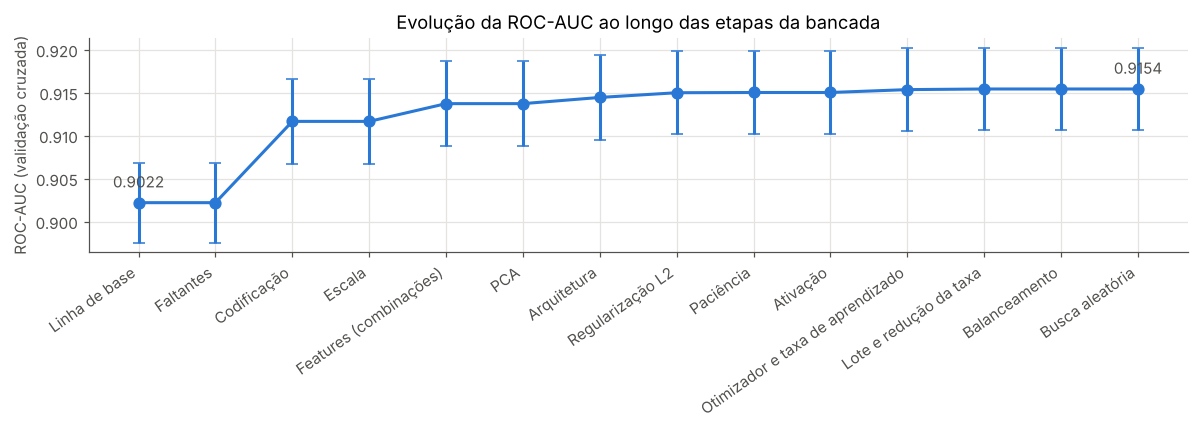

In [32]:
fig, ax = plt.subplots(figsize=(11, 4))
pos = np.arange(len(evolucao))
ax.errorbar(pos, evolucao["roc_auc"], yerr=evolucao["roc_auc_dp"], color=AZUL, marker="o",
            markersize=7, capsize=4, label="ROC-AUC da melhor variação da etapa")
ax.set_xticks(pos, [e.split(". ")[1] if ". " in e else e for e in evolucao.index], rotation=35, ha="right")
ax.set_ylabel("ROC-AUC (validação cruzada)")
ax.set_title("Evolução da ROC-AUC ao longo das etapas da bancada")
for i, v in enumerate(evolucao["roc_auc"]):
    if i in (0, len(evolucao) - 1):
        ax.annotate(f"{v:.4f}", (i, v), textcoords="offset points", xytext=(0, 10), ha="center", color=CINZA_TEXTO)
plt.tight_layout()
plt.show()

**Análise:** a ROC-AUC subiu de 0,9022 para 0,9154 (+0,0132). Cerca de **87% do ganho vem do tratamento dos dados**: a codificação *one-hot* (+0,0095) e o indicador de ganho de capital (+0,0020). Arquitetura, regularização e otimização juntas somam +0,0017 — real, mas pequeno, e cada passo isolado está no limite do ruído.

## Etapa 12 — Limiar de decisão

A rede devolve uma probabilidade; o limiar 0,5 é só uma convenção. Usando as **previsões fora-do-fold** da melhor configuração (cada exemplo do treino foi previsto por um modelo que não o viu), escolhemos o limiar que maximiza:

- o **F1** (equilíbrio entre precisão e recall da classe `>50K`);
- a **acurácia**.

Isso é feito só com dados de treino, então o teste continua intocado.

In [33]:
oof = bancada.oof_melhor()
limiares = np.round(np.arange(0.05, 0.951, 0.01), 2)
curvas = pd.DataFrame([calcular_metricas(y_treino, oof, t) for t in limiares], index=limiares)

limiar_f1 = curvas["f1"].idxmax()
limiar_acc = curvas["acuracia"].idxmax()
print(f"Limiar que maximiza o F1:       {limiar_f1:.2f}")
print(f"Limiar que maximiza a acurácia: {limiar_acc:.2f}")
curvas.loc[sorted({0.5, limiar_f1, limiar_acc}), ["acuracia", "precisao", "recall", "f1", "mcc", "acuracia_bal"]].round(4)

Limiar que maximiza o F1:       0.40
Limiar que maximiza a acurácia: 0.44


,acuracia,precisao,recall,f1,mcc,acuracia_bal
0.40,0.8553,0.6901,0.7247,0.7070,0.6114,0.8107
0.44,0.8590,0.7150,0.6891,0.7018,0.6097,0.8010
0.50,0.8583,0.7461,0.6236,0.6794,0.5933,0.7782


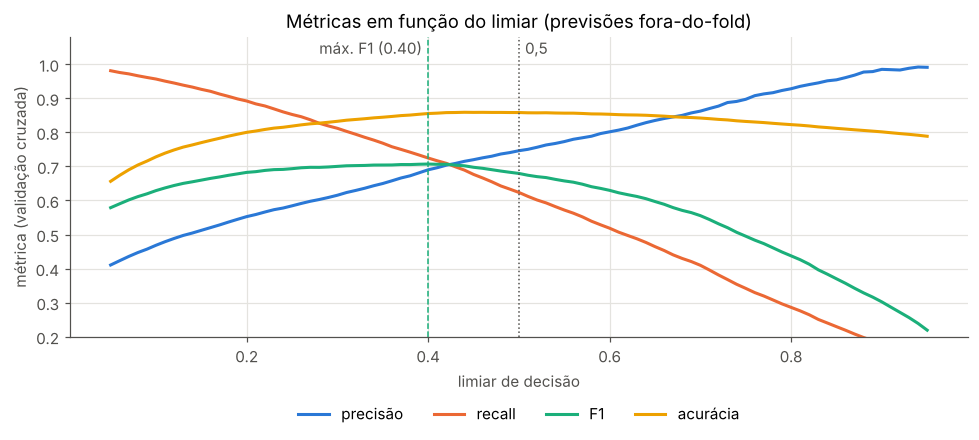

In [34]:
fig, ax = plt.subplots(figsize=(9, 4.2))
for col, cor, nome in [("precisao", AZUL, "precisão"), ("recall", LARANJA, "recall"),
                       ("f1", VERDE_AGUA, "F1"), ("acuracia", AMARELO, "acurácia")]:
    ax.plot(curvas.index, curvas[col], color=cor, label=nome)
ax.axvline(0.5, color=CINZA_TEXTO, lw=1, ls=":")
ax.axvline(limiar_f1, color=VERDE_AGUA, lw=1, ls="--")
ax.annotate(f"máx. F1 ({limiar_f1:.2f})", (limiar_f1, 1.02), xytext=(-4, 0), textcoords="offset points",
            ha="right", va="bottom", color=CINZA_TEXTO)
ax.annotate("0,5", (0.5, 1.02), xytext=(4, 0), textcoords="offset points", va="bottom", color=CINZA_TEXTO)
ax.set(xlabel="limiar de decisão", ylabel="métrica (validação cruzada)", ylim=(0.2, 1.08),
       title="Métricas em função do limiar (previsões fora-do-fold)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=4, frameon=False)
plt.tight_layout()
plt.show()

**Análise:** o limiar muda muito mais as métricas do que qualquer hiperparâmetro da rede. Baixar o limiar de 0,5 para **0,40** aumenta o F1 de 0,679 para 0,707 e o recall de 0,62 para 0,72, com a acurácia praticamente igual (0,858 → 0,855). O limiar de 0,44 maximiza a acurácia, mas o ganho é mínimo (0,8583 → 0,8590). A escolha do limiar depende do uso: se perder uma pessoa de renda alta custa mais caro, um limiar ainda menor aumenta o recall à custa da precisão.

## Estabilidade da melhor configuração

Repetimos a validação cruzada da melhor configuração com outras sementes (novas divisões dos folds e novas inicializações da rede). A variação entre sementes mostra quanto das diferenças entre experimentos é ruído.

In [35]:
estab = []
for semente in [1, 2, 3, 4, 5]:
    r = avaliar_cv(X_treino, y_treino, melhor_cfg, n_folds=5, seed=semente)
    estab.append({"semente": semente, **{m: r[m] for m in ["roc_auc", "pr_auc", "acuracia", "f1"]}})
estab = pd.DataFrame(estab).set_index("semente")
print(estab.round(4))
print("\nMédia ± desvio-padrão:")
print((estab.mean().round(4).astype(str) + " ± " + estab.std().round(4).astype(str)).to_string())

         roc_auc  pr_auc  acuracia      f1
semente                                   
1         0.9140  0.7871    0.8585  0.6805
2         0.9147  0.7879    0.8595  0.6870
3         0.9147  0.7888    0.8587  0.6790
4         0.9152  0.7887    0.8590  0.6804
5         0.9151  0.7899    0.8586  0.6831

Média ± desvio-padrão:
roc_auc     0.9147 ± 0.0005
pr_auc       0.7885 ± 0.001
acuracia    0.8589 ± 0.0004
f1           0.682 ± 0.0032


**Análise:** com outras sementes, a ROC-AUC da melhor configuração varia ~0,0005 (desvio-padrão). Portanto, diferenças menores que ~0,001 entre experimentos **não são conclusivas** — é o caso da maioria dos ajustes de arquitetura, regularização e otimização. Já os ganhos da codificação (+0,0095) e do indicador de capital (+0,0020) estão muito acima desse ruído.

## Modelo final e avaliação no teste

O modelo final usa a melhor configuração, treinada em todo o conjunto de treino. Como a inicialização aleatória dos pesos muda um pouco o resultado, treinamos **5 redes com sementes diferentes** e usamos a **média das probabilidades** (ensemble de sementes) — uma técnica simples que costuma melhorar e estabilizar as métricas.

In [36]:
SEMENTES = [0, 1, 2, 3, 4]
treinados = treinar_sementes(X_treino, y_treino, melhor_cfg, SEMENTES)  # em paralelo
modelos, probas_teste = [], []
for s, (prep, rede, n_ep) in zip(SEMENTES, treinados):
    modelos.append((prep, rede))
    probas_teste.append(prever_proba(prep, rede, X_teste))
    print(f"semente {s}: {n_ep} épocas, ROC-AUC no teste = {calcular_metricas(y_teste, probas_teste[-1])['roc_auc']:.4f}")
proba_ensemble = np.mean(probas_teste, axis=0)

semente 0: 199 épocas, ROC-AUC no teste = 0.9206
semente 1: 199 épocas, ROC-AUC no teste = 0.9205
semente 2: 194 épocas, ROC-AUC no teste = 0.9210
semente 3: 194 épocas, ROC-AUC no teste = 0.9210
semente 4: 199 épocas, ROC-AUC no teste = 0.9212


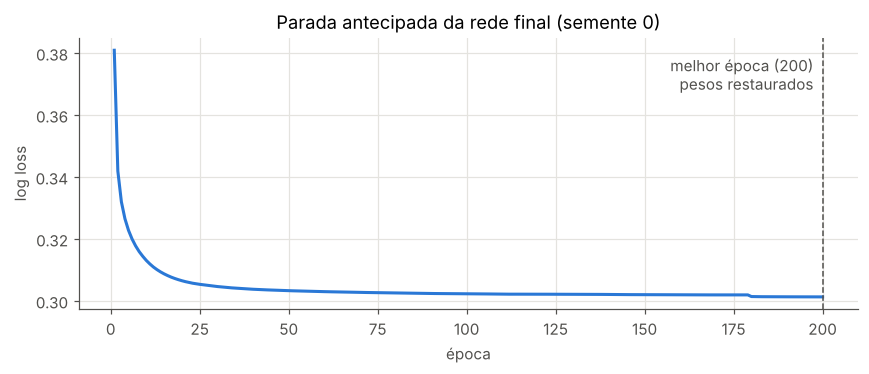

In [37]:
# Curva de aprendizado de uma das redes: perda no conjunto de parada antecipada a cada época
rede = modelos[0][1]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(np.arange(1, len(rede.curva_perda_) + 1), rede.curva_perda_, color=AZUL, label="perda de validação")
melhor_ep = int(np.argmin(rede.curva_perda_)) + 1
ax.axvline(melhor_ep, color=CINZA_TEXTO, ls="--", lw=1)
ax.annotate(f"melhor época ({melhor_ep})\npesos restaurados", (melhor_ep, max(rede.curva_perda_)),
            xytext=(-6, -4), textcoords="offset points", color=CINZA_TEXTO, va="top", ha="right")
ax.set(xlabel="época", ylabel="log loss", title="Parada antecipada da rede final (semente 0)")
plt.tight_layout()
plt.show()

**Análise:** a perda cai rapidamente nas primeiras ~30 épocas e depois fica quase plana. O pequeno degrau perto da época 180 é a redução da taxa de aprendizado. Com taxa 3e-4 e L2 alto, a rede ainda melhora de forma ínfima até o limite de 200 épocas: aumentar esse limite pouco mudaria o resultado.

In [38]:
linhas = {
    "MLP final, 1 rede (média das 5 sementes), limiar 0,5":
        pd.DataFrame([calcular_metricas(y_teste, p) for p in probas_teste]).mean(),
    "MLP final, ensemble de 5 sementes, limiar 0,5": pd.Series(calcular_metricas(y_teste, proba_ensemble)),
    f"MLP final, ensemble, limiar máx. F1 ({limiar_f1:.2f})": pd.Series(calcular_metricas(y_teste, proba_ensemble, limiar_f1)),
    f"MLP final, ensemble, limiar máx. acurácia ({limiar_acc:.2f})": pd.Series(calcular_metricas(y_teste, proba_ensemble, limiar_acc)),
}
tabela_teste = pd.DataFrame(linhas).T[METRICAS]
tabela_teste.round(4)

,acuracia,acuracia_bal,precisao,recall,f1,mcc,roc_auc,pr_auc,log_loss
"MLP final, 1 rede (média das 5 sementes), limiar 0,5",0.8654,0.7921,0.7564,0.6508,0.6994,0.6163,0.9209,0.8071,0.2945
"MLP final, ensemble de 5 sementes, limiar 0,5",0.8658,0.7910,0.7601,0.6467,0.6988,0.6165,0.9212,0.8078,0.2939
"MLP final, ensemble, limiar máx. F1 (0.40)",0.8575,0.8215,0.6863,0.7519,0.7176,0.6237,0.9212,0.8078,0.2939
"MLP final, ensemble, limiar máx. acurácia (0.44)",0.8612,0.8097,0.7123,0.7105,0.7114,0.6200,0.9212,0.8078,0.2939


**Análise (teste, nunca usado nas escolhas):**

- **ROC-AUC 0,9212 e PR-AUC 0,8078** com o ensemble de 5 sementes. Os valores no teste ficam um pouco acima da validação cruzada (0,915) porque o modelo final usa 100% do treino, e porque a divisão de teste varia naturalmente.
- O ensemble ganha pouco sobre uma rede só (0,9209 → 0,9212): com L2 alto, as redes já são estáveis.
- **No limiar 0,40** (escolhido na validação para maximizar o F1): F1 0,718, recall 0,752, precisão 0,686, acurácia 0,858 e o maior MCC (0,624).
- **No limiar 0,5:** acurácia 0,866 e precisão 0,760, mas recall de só 0,647.

In [39]:
pred_final = (proba_ensemble >= limiar_f1).astype(int)
print(classification_report(y_teste, pred_final, target_names=["<=50K", ">50K"], digits=4))

              precision    recall  f1-score   support

       <=50K     0.9189    0.8910    0.9047      4945
        >50K     0.6863    0.7519    0.7176      1568

    accuracy                         0.8575      6513
   macro avg     0.8026    0.8215    0.8112      6513
weighted avg     0.8629    0.8575    0.8597      6513



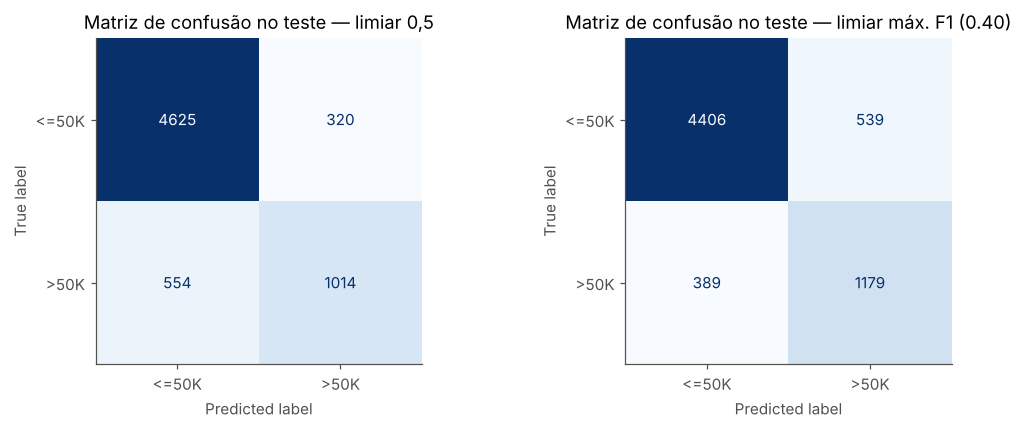

In [40]:
fig, eixos = plt.subplots(1, 2, figsize=(10, 4))
for ax, limiar, titulo in [(eixos[0], 0.5, "limiar 0,5"), (eixos[1], limiar_f1, f"limiar máx. F1 ({limiar_f1:.2f})")]:
    ConfusionMatrixDisplay.from_predictions(
        y_teste, (proba_ensemble >= limiar).astype(int), display_labels=["<=50K", ">50K"],
        cmap="Blues", colorbar=False, ax=ax)
    ax.grid(False)
    ax.set_title(f"Matriz de confusão no teste — {titulo}")
plt.tight_layout()
plt.show()

## Comparação com outros modelos

Para situar o resultado da rede, avaliamos no **mesmo teste**:

- a **MLP da linha de base** (configuração inicial, sem as melhorias da bancada);
- a **regressão logística** do notebook de PCA (`LabelEncoder` + `StandardScaler`) e a mesma com *one-hot*;
- a **Random Forest** do tutorial (`LabelEncoder`);
- o **HistGradientBoosting**, um modelo de *boosting* de árvores, que costuma ser a referência mais forte em dados tabulares.

In [41]:
def pipeline_sklearn(modelo, codificacao="onehot", escala=True):
    if codificacao == "onehot":
        cod = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    else:
        cod = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    cat = Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("cod", cod)]
                   + ([("esc", StandardScaler())] if escala and codificacao != "onehot" else []))
    num = StandardScaler() if escala else "passthrough"
    colunas = ColumnTransformer([("num", num, make_column_selector(dtype_include="number")),
                                 ("cat", cat, make_column_selector(dtype_exclude="number"))])
    return Pipeline([("colunas", colunas), ("modelo", modelo)])

referencias = {
    "Regressão logística (label, como no notebook de PCA)":
        pipeline_sklearn(LogisticRegression(max_iter=2000), "label"),
    "Regressão logística (one-hot)":
        pipeline_sklearn(LogisticRegression(max_iter=2000), "onehot"),
    "Random Forest (label, como no tutorial)":
        pipeline_sklearn(RandomForestClassifier(random_state=2022, n_jobs=-1), "label", escala=False),
    "HistGradientBoosting (label)":
        pipeline_sklearn(HistGradientBoostingClassifier(random_state=RANDOM_STATE), "label", escala=False),
}
probas_ref = {}
for nome, modelo in referencias.items():
    modelo.fit(X_treino, y_treino)
    probas_ref[nome] = modelo.predict_proba(X_teste)[:, 1]

# MLP da linha de base, treinada no treino completo
prep0, rede0, _ = treinar_modelo(X_treino, y_treino, CONFIG_BASE, seed=0)
probas_ref["MLP linha de base (label + standard, 64-32)"] = prever_proba(prep0, rede0, X_teste)
probas_ref["MLP final (ensemble de 5 sementes)"] = proba_ensemble

comparacao = pd.DataFrame({nome: calcular_metricas(y_teste, p) for nome, p in probas_ref.items()}).T
comparacao = comparacao[METRICAS].sort_values("roc_auc", ascending=False)
print("Todas as métricas com limiar 0,5 (exceto ROC-AUC, PR-AUC e log loss, que não dependem do limiar)")
comparacao.round(4)

Todas as métricas com limiar 0,5 (exceto ROC-AUC, PR-AUC e log loss, que não dependem do limiar)


,acuracia,acuracia_bal,precisao,recall,f1,mcc,roc_auc,pr_auc,log_loss
HistGradientBoosting (label),0.8743,0.8031,0.7797,0.6658,0.7183,0.6413,0.9294,0.8342,0.2750
MLP final (ensemble de 5 sementes),0.8658,0.7910,0.7601,0.6467,0.6988,0.6165,0.9212,0.8078,0.2939
"Random Forest (label, como no tutorial)",0.8610,0.7892,0.7407,0.6505,0.6927,0.6055,0.9114,0.7926,0.3203
Regressão logística (one-hot),0.8558,0.7744,0.7406,0.6173,0.6734,0.5858,0.9078,0.7732,0.3160
"MLP linha de base (label + standard, 64-32)",0.8494,0.7736,0.7125,0.6276,0.6673,0.5724,0.9048,0.7703,0.3208
"Regressão logística (label, como no notebook de PCA)",0.8274,0.7021,0.7220,0.4605,0.5623,0.4794,0.8616,0.7018,0.3746


**Análise da comparação:**

- A bancada melhorou a rede em todas as métricas em relação à MLP da linha de base: ROC-AUC 0,9048 → 0,9212, PR-AUC 0,770 → 0,808, acurácia 0,849 → 0,866, F1 0,667 → 0,699 (limiar 0,5) e 0,718 com o limiar ajustado.
- A rede final supera os modelos dos notebooks de referência: a regressão logística com `LabelEncoder` (acurácia 0,827; o notebook relatou 0,822) e a Random Forest do tutorial (acurácia 0,861; o tutorial relatou 0,857 em outra divisão).
- Usar *one-hot* também melhora muito a regressão logística (ROC-AUC 0,862 → 0,908), o que confirma que a codificação é o ponto principal.
- **O HistGradientBoosting continua sendo o melhor modelo** (ROC-AUC 0,929, acurácia 0,874), sem nenhum ajuste. Em dados tabulares com muitas variáveis categóricas e limiares bem definidos (como ganho de capital), modelos de *boosting* de árvores costumam superar redes MLP. A rede otimizada fica a ~0,008 de ROC-AUC dele.

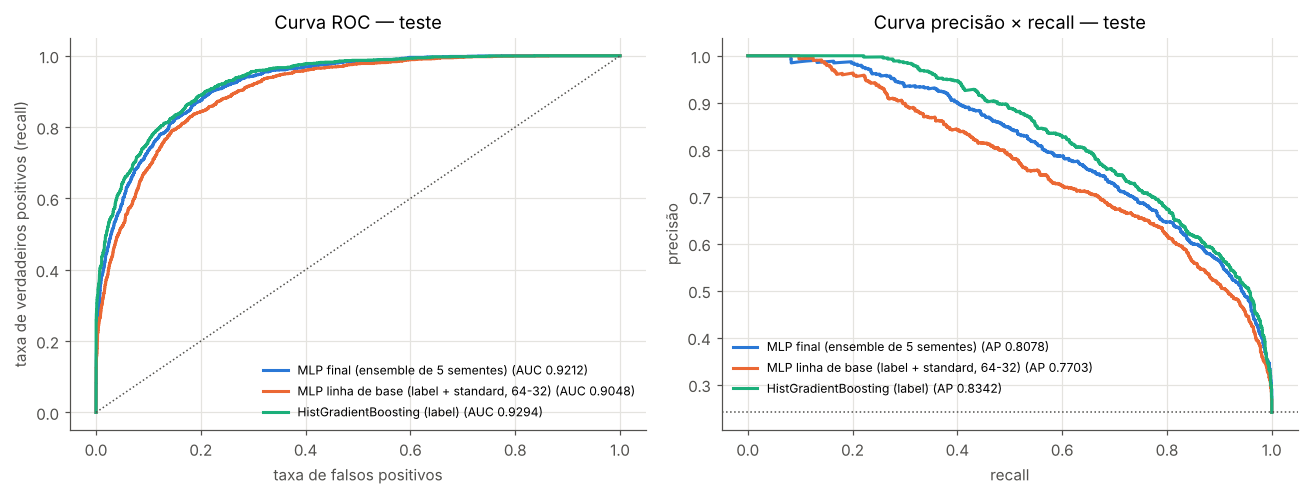

In [42]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.6))
destaque = {"MLP final (ensemble de 5 sementes)": AZUL,
            "MLP linha de base (label + standard, 64-32)": LARANJA,
            "HistGradientBoosting (label)": VERDE_AGUA}
for nome, cor in destaque.items():
    p = probas_ref[nome]
    fpr, tpr, _ = roc_curve(y_teste, p)
    eixos[0].plot(fpr, tpr, color=cor, label=f"{nome} (AUC {comparacao.loc[nome, 'roc_auc']:.4f})")
    prec, rec, _ = precision_recall_curve(y_teste, p)
    eixos[1].plot(rec, prec, color=cor, label=f"{nome} (AP {comparacao.loc[nome, 'pr_auc']:.4f})")
eixos[0].plot([0, 1], [0, 1], color=CINZA_TEXTO, lw=1, ls=":")
eixos[0].set(xlabel="taxa de falsos positivos", ylabel="taxa de verdadeiros positivos (recall)", title="Curva ROC — teste")
eixos[1].axhline(y_teste.mean(), color=CINZA_TEXTO, lw=1, ls=":")
eixos[1].set(xlabel="recall", ylabel="precisão", title="Curva precisão × recall — teste")
for ax in eixos:
    ax.legend(loc="lower left" if ax is eixos[1] else "lower right", fontsize=8, frameon=False,
              bbox_to_anchor=(0, 0.06) if ax is eixos[1] else None)
plt.tight_layout()
plt.show()

## Conclusões

**Melhor configuração encontrada para a rede neural**

| Aspecto | Escolha |
|---|---|
| Valores faltantes | moda (as alternativas empatam) |
| Codificação | *one-hot* |
| Escala | `StandardScaler` |
| Engenharia de features | indicadores 0/1 de ganho e de perda de capital |
| PCA | não usar |
| Arquitetura | 1 camada oculta com 256 neurônios, ReLU |
| Regularização | L2 = 0,3 + parada antecipada (paciência 30) |
| Otimização | Adam, taxa 3e-4, lote 256, redução da taxa em platôs |
| Balanceamento | nenhum (usar o ajuste do limiar) |
| Limiar | 0,40 para maximizar o F1; 0,5 para maximizar a precisão/acurácia |
| Modelo final | média de 5 redes com sementes diferentes |

**Resultado no teste:** ROC-AUC 0,921, PR-AUC 0,808, acurácia 0,866 (limiar 0,5) e F1 0,718 com recall 0,752 (limiar 0,40) — contra ROC-AUC 0,905 e F1 0,667 da rede com o pré-processamento dos notebooks de referência.

**O que mais influenciou as métricas**

1. **Codificação das categóricas:** *one-hot* no lugar de `LabelEncoder` foi, sozinho, responsável pela maior parte do ganho.
2. **Limiar de decisão:** muda F1 e recall muito mais do que qualquer hiperparâmetro (F1 +0,03, recall +0,10 na validação).
3. **Engenharia de features simples e bem motivada pela análise exploratória:** os indicadores de capital ajudaram; transformações genéricas (log, agrupamentos, faixas, todas juntas) não ajudaram ou pioraram.
4. **Hiperparâmetros da rede:** depois de um pré-processamento bom, os ganhos são pequenos (platô em ~0,915 de ROC-AUC na validação). Uma camada larga com regularização L2 forte foi suficiente.

**O que não funcionou:** PCA, log nas colunas de capital, `MinMaxScaler`, ativação sigmoide, lotes pequenos, e balanceamento de classes como forma de aumentar a ROC-AUC (ele só desloca o limiar).

**Próximos passos possíveis**

- *Embeddings* para as variáveis categóricas, *dropout* e *batch normalization* (exigem Keras ou PyTorch).
- Combinar a rede com o HistGradientBoosting (média das probabilidades), já que os dois modelos erram de formas diferentes.
- Otimização bayesiana dos hiperparâmetros (ex.: Optuna) e validação cruzada repetida, para separar melhor ganhos pequenos do ruído.
- Calibração das probabilidades, se elas forem usadas diretamente (e não só para classificar).